# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** [Moh Reza]
- **Email:** [mohreza2455@gmail.com]
- **ID Dicoding:** [DS323B6Y1011]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Apa yang terjadi pada tren penjualan pada tahun 2011 - 2012, bulan apa yang menjadi puncak ketinggian dan terendah, berapa persen pertumbuhan yang terjadi setelah tahun 2011 yaitu pada tahun 2012, agar pada pihak manajemen dapat menyesuaikan stok dan jadwal perawatan sepeda
- **Pertanyaan 2:** xxx
- ...

## Import Semua Packages/Library yang Digunakan

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [11]:
day_df = pd.read_csv("sample_data/day.csv")
hour_df = pd.read_csv("sample_data/hour.csv")
day_df.head()
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- day_df berisi 731 baris dan 16 kolom (data harian, 1 Januari 2011 sampai 31 Desember 2012). hour_df berisi 17.379 baris dan 17 kolom (data per jam, dengan tambahan kolom hr).
- Kolom utama: cnt (total penyewaan) = casual + registered, serta variabel cuaca (temp, hum, windspeed, weathersit).

### Assessing Data

#### Identifying ... problem

In [12]:
for name, df in [("day_df", day_df), ("hour_df", hour_df)]:
    print(f"=== {name} ===")
    df.info()
    print("Missing value:\n", df.isna().sum())
    print("Duplikat:", df.duplicated().sum())
    print()
day_df.describe()

Q1, Q3 = day_df['windspeed'].quantile([0.25, 0.75])
IQR = Q3 - Q1
outliers = day_df[(day_df['windspeed'] < Q1 - 1.5*IQR) | (day_df['windspeed'] > Q3 + 1.5*IQR)]
print("Jumlah outlier windspeed:", len(outliers))

=== day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
Missing value:
 instant       0
dteday        0
season        0
yr            

**Steps to Take:**
- Mengubah tipe data dteday dari object menjadi datetime
- Mengubah kode angka pada season, yr, weathersit menjadi label yang mudah dibaca
- Mengonversi temp, hum, windspeed dari skala ternormalisasi ke satuan asli
- Outlier windspeed dibiarkan karena masih nilai wajar (tulis alasanmu)

**Insight:** (Opsional)
- Tidak ada missing value maupun data duplikat di kedua tabel.
- dteday bertipe object, padahal seharusnya datetime.
- season, weathersit, dan workingday masih berupa kode angka. temp, hum, dan windspeed masih ternormalisasi (0–1).
- Ada 13 outlier windspeed (sekitar 1,8% dari 731 hari). Jumlahnya kecil dan mewakili hari berangin kencang yang wajar, jadi dibiarkan.


### Cleaning Data

#### Fixing ... problem

In [13]:

day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

for df in (day_df, hour_df):
    df['season'] = df['season'].map({1:'Spring', 2:'Summer', 3:'Fall', 4:'Winter'})
    df['yr'] = df['yr'].map({0:2011, 1:2012})
    df['weathersit'] = df['weathersit'].map({1:'Clear', 2:'Mist/Cloudy', 3:'Light Rain/Snow', 4:'Heavy Rain'})
    df['day_type'] = df['workingday'].map({1:'Hari Kerja', 0:'Akhir Pekan/Libur'})
    df['temp_c'] = df['temp'] * 41
    df['hum_pct'] = df['hum'] * 100
    df['wind_kmh'] = df['windspeed'] * 67

day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    object        
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    object        
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
 16  day_type    731 non-null  

**Insight:** (Opsional)
- dteday kini bertipe datetime64, season dan weathersit berupa label teks, dan kolom bertambah dari 16 menjadi 20 (day_type, temp_c, hum_pct, wind_kmh).
- Catatan: pada day_df tidak muncul kategori Heavy Rain, jadi hanya ada tiga kondisi cuaca.

In [14]:
day_df.to_csv("main_data.csv", index=False)
hour_df.to_csv("hour_clean.csv", index=False)

## Exploratory Data Analysis (EDA)

In [15]:
# Ringkasan statistik
day_df[['cnt','casual','registered','temp_c','hum_pct','wind_kmh']].describe()

,cnt,casual,registered,temp_c,hum_pct,wind_kmh
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,4504.348837,848.176471,3656.172367,20.310776,62.789406,12.762576
std,1937.211452,686.622488,1560.256377,7.505091,14.242910,5.192357
min,22.000000,2.000000,20.000000,2.424346,0.000000,1.500244
25%,3152.000000,315.500000,2497.000000,13.820424,52.000000,9.041650
50%,4548.000000,713.000000,3662.000000,20.431653,62.666700,12.125325
75%,5956.000000,1096.000000,4776.500000,26.872076,73.020850,15.625371
max,8714.000000,3410.000000,6946.000000,35.328347,97.250000,34.000021


### Explore ...

In [16]:
# Untuk Pertanyaan 1: tren bulanan
monthly = day_df.resample('ME', on='dteday')['cnt'].sum().reset_index()
print("Bulan tertinggi:\n", monthly.sort_values('cnt', ascending=False).head(3))
print("Bulan terendah:\n", monthly.sort_values('cnt').head(3))

total_by_year = day_df.groupby('yr')['cnt'].sum()
growth = (total_by_year[2012] - total_by_year[2011]) / total_by_year[2011] * 100
print(f"Pertumbuhan 2012 vs 2011: {growth:.1f}%")



Bulan tertinggi:
        dteday     cnt
20 2012-09-30  218573
19 2012-08-31  214503
18 2012-07-31  203607
Bulan terendah:
       dteday    cnt
0 2011-01-31  38189
1 2011-02-28  48215
2 2011-03-31  64045
Pertumbuhan 2012 vs 2011: 64.9%


**Insight:** (Opsional)
- Tiga bulan tertinggi semuanya di 2012: September (218.573), Agustus (214.503), dan Juli (203.607).
- Tiga bulan terendah semuanya di awal 2011: Januari (38.189), Februari (48.215), dan Maret (64.045).
- Total penyewaan 2012 naik 64,9% dibanding 2011.
- Bulan puncak (September 2012) sekitar 5,7 kali lipat bulan terendah (Januari 2011).

## Visualization & Explanatory Analysis

### Pertanyaan 1:

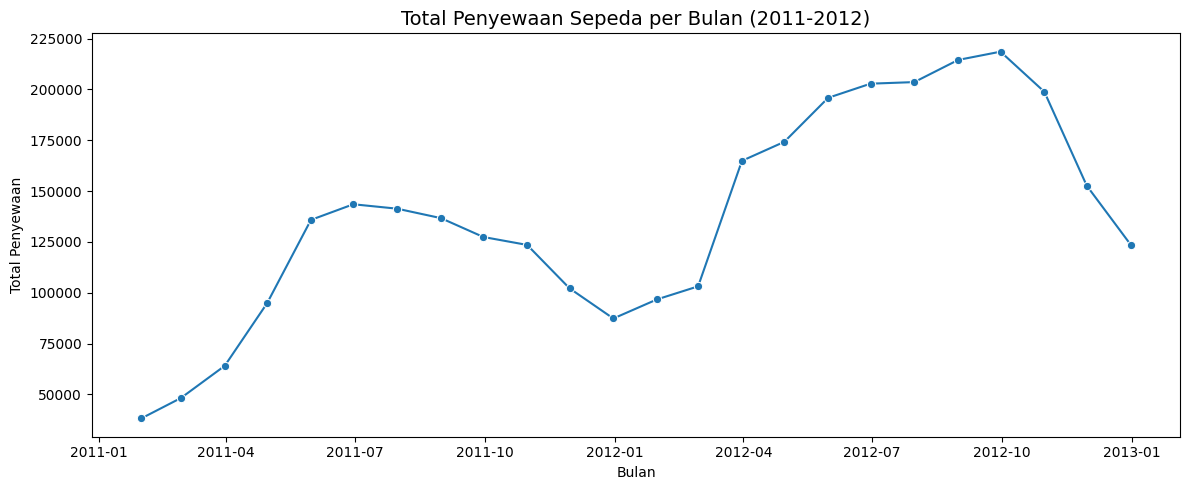

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=monthly, x='dteday', y='cnt', marker='o', ax=ax)
ax.set_title('Total Penyewaan Sepeda per Bulan (2011-2012)', fontsize=14)
ax.set_xlabel('Bulan')
ax.set_ylabel('Total Penyewaan')
plt.tight_layout()
plt.show()

### Pertanyaan 2:

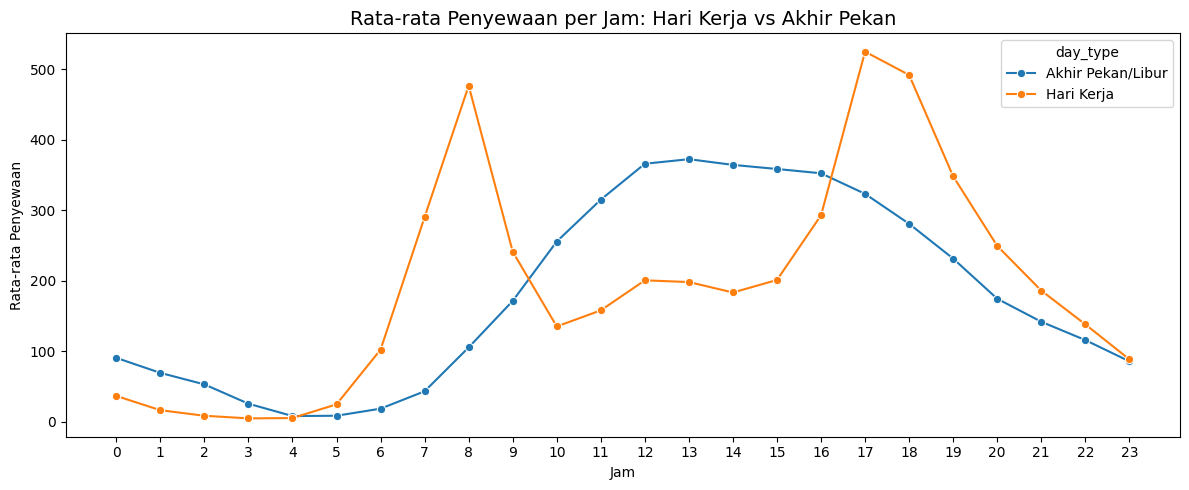

In [18]:
hourly = hour_df.groupby(['hr', 'day_type'])['cnt'].mean().reset_index()
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=hourly, x='hr', y='cnt', hue='day_type', marker='o', ax=ax)
ax.set_title('Rata-rata Penyewaan per Jam: Hari Kerja vs Akhir Pekan', fontsize=14)
ax.set_xlabel('Jam')
ax.set_ylabel('Rata-rata Penyewaan')
ax.set_xticks(range(0, 24))
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
Pertanyaan 1
- Grafik menunjukkan dua gelombang: naik dari awal 2011 hingga puncak sekitar Juni-Juli 2011 (±145.000), turun sampai titik terendah sekitar Januari 2012 (±87.000), lalu naik lagi lebih tinggi hingga puncak sekitar Oktober 2012 (±218.000).
- Pola naik di bulan hangat dan turun di bulan dingin berulang di kedua tahun, menandakan permintaan bersifat musiman.
- Seluruh titik 2012 berada di atas titik bulan yang sama di 2011, sehingga tren jangka panjangnya tumbuh, bukan hanya musiman.
- Setelah puncak di akhir 2012, penyewaan turun cepat memasuki musim dingin.

Pertanyaan 2
- Hari kerja punya dua puncak tajam: pagi di jam 8 (±477) dan sore di jam 17 (±525), dengan jam 18 (±492) juga tinggi. Pola ini khas jam berangkat dan pulang kerja.
- Di antara dua puncak (jam 10-15), hari kerja turun ke ±135-200 penyewaan.
Akhir pekan/libur tidak punya puncak pagi. Penyewaan naik perlahan dan memuncak di siang hari, jam 12-14 (±365-373), lalu menurun menjelang malam. Pola ini khas rekreasi.
- Pada dini hari (jam 0-3) akhir pekan justru lebih ramai dari hari kerja, dan keduanya hampir sama di jam 23.

## Analisis Lanjutan (Opsional)

In [19]:
# Binning suhu
day_df['temp_category'] = pd.cut(day_df['temp_c'], bins=[0, 15, 25, 50],
                                 labels=['Dingin', 'Sedang', 'Panas'])
print(day_df.groupby('temp_category', observed=True)['cnt'].agg(['count', 'mean']))

# Clustering manual: level permintaan harian
day_df['demand_level'] = pd.qcut(day_df['cnt'], q=3, labels=['Rendah', 'Sedang', 'Tinggi'])
print(day_df['demand_level'].value_counts())
print(day_df.groupby(['season', 'demand_level'], observed=True).size().unstack())

               count         mean
temp_category                    
Dingin           221  2833.316742
Sedang           268  4863.951493
Panas            242  5632.136364
demand_level
Rendah    244
Sedang    244
Tinggi    243
Name: count, dtype: int64
demand_level  Rendah  Sedang  Tinggi
season                              
Fall              13      79      96
Spring           140      33       8
Summer            37      71      76
Winter            54      61      63


**Insight:** (Opsional)
- Binning suhu: rata-rata harian Dingin (<15°C) 2.833, Sedang (15-25°C) 4.864, Panas (>25°C) 5.632. Penyewaan naik seiring suhu, dengan lonjakan terbesar dari Dingin ke Sedang (sekitar +72%), sedangkan Sedang ke Panas hanya sekitar +16%.
- Ini konsisten dengan korelasi suhu-cnt sebesar 0,63 di tahap EDA.
- Demand level (qcut): hari terbagi hampir sama rata (244/244/243) karena qcut memang membagi berdasarkan kuantil, jadi yang diamati adalah komposisinya per musim.
- Spring didominasi permintaan Rendah (140 dari 181 hari), sedangkan Fall paling sering Tinggi (96 dari 188 hari). Summer dan Winter lebih merata.
- Catatan di markdown: label musim mengikuti dokumentasi dataset (season=1 dimulai dari Januari).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Penyewaan memuncak pada September 2012 (218.573) dan terendah pada Januari 2011 (38.189). Total 2012 naik 64,9% dibanding 2011, dan polanya musiman: tinggi di bulan hangat (Juli-September), rendah di bulan dingin (Januari-Maret).
- **Conclusion pertanyaan 2:** Hari kerja berpola komuter dengan puncak di jam 8 (±477) dan jam 17-18 (puncak tertinggi ±525 di jam 17), sedangkan akhir pekan berpola rekreasi dengan puncak di jam 12-14 (±365-373).
- ...

**Rekomendasi Action Item:**
- Pastikan ketersediaan sepeda maksimal di titik perkantoran dan transit pada jam 07-09 dan 16-19 di hari kerja, serta geser sebagian armada ke area wisata/taman pada jam 11-15 di akhir pekan.
- Jadwalkan perawatan armada massal di bulan dingin (Januari-Maret) saat permintaan rendah, dan siapkan stok penuh sebelum Juli-September.
- Buat promo atau paket langganan untuk hari dingin (<15°C) dan musim dengan permintaan rendah untuk menjaga pendapatan.